# 01 · Dataset exploration

Quick checks on CIFAR-10, CIFAR-100 and SVHN before writing the split and training code. Each section answers one question that feeds a decision.

Data lives in `../data/`. No model or training in this notebook.

## Setup

In [1]:
import platform                                                     # platform: OS and Python version info
import torch                                                        # torch: PyTorch, only to report its version and MPS support
import torchvision                                                  # torchvision: only to report its version

print(f"Python:        {platform.python_version()}")                # Python version
print(f"OS:            {platform.platform()}")                      # macOS version and chip architecture
print(f"PyTorch:       {torch.__version__}")                        # PyTorch version
print(f"torchvision:   {torchvision.__version__}")                  # torchvision version
print(f"MPS available: {torch.backends.mps.is_available()}")        # True if the Apple GPU can be used

SEED = 0                                                            # one seed for every random choice in this notebook
COLORS = {"CIFAR-10": "#2a78d6", "CIFAR-100": "#eb6834", "SVHN": "#1baf7a"}  # one fixed color per dataset in every plot

Python:        3.11.18
OS:            macOS-26.6.2-arm64-arm-64bit
PyTorch:       2.15.0
torchvision:   0.29.2
MPS available: True


## 1. Load all three and verify

**Looking for:** train/test counts (CIFAR-10 50k/10k, CIFAR-100 50k/10k, SVHN 73,257/26,032), image shape 32×32×3, data type, label range (SVHN labels must be 0–9, no label 10).

**Feeds:** catches loading bugs before any training.

In [2]:
import sys          # sys: information about the running Python
print(sys.executable)

/Users/egekaradibak/PaintLab/experiments/pretrain-retention/cl-relearning/.venv/bin/python


In [3]:
from pathlib import Path                         # Path: handles file and folder paths cleanly
import time                                      # time: measures how long things take (section 6)
import numpy as np                               # numpy: fast math on arrays of numbers (images, labels)
import matplotlib.pyplot as plt                  # matplotlib: draws plots and image grids
from torchvision import datasets, transforms as T  # datasets: CIFAR/SVHN loaders; T: image augmentations
from torch.utils.data import DataLoader, Subset  # DataLoader: serves data in batches; Subset: picks part of a dataset

DATA = Path("../data")                           # the data folder, one level up from notebooks/

# Training sets (no transform → each item is a PIL image and its label)
c10 = datasets.CIFAR10(DATA, train=True, download=False)            # CIFAR-10 train, already on disk
c100 = datasets.CIFAR100(DATA, train=True, download=False)          # CIFAR-100 train, already on disk
svhn = datasets.SVHN(DATA / "svhn", split="train", download=False)  # SVHN train; its files are in data/svhn/

# Test sets
c10_test = datasets.CIFAR10(DATA, train=False, download=False)            # CIFAR-10 test
c100_test = datasets.CIFAR100(DATA, train=False, download=False)          # CIFAR-100 test
svhn_test = datasets.SVHN(DATA / "svhn", split="test", download=False)    # SVHN test

# SVHN has no .classes attribute, so add one: the 10 classes are the digits 0–9
svhn_classes = [str(d) for d in range(10)]       # ["0", "1", ..., "9"]; label k means digit k
svhn.classes = svhn_classes                      # attach to the train set so it works like CIFAR's .classes
svhn_test.classes = svhn_classes                 # same for the test set


In [4]:
print("=== Number of images ===")                                   # title for this check
print(f"CIFAR-10:  train={len(c10)}, test={len(c10_test)}")          # expected 50000 / 10000
print(f"CIFAR-100: train={len(c100)}, test={len(c100_test)}")        # expected 50000 / 10000
print(f"SVHN:      train={len(svhn)}, test={len(svhn_test)}")        # expected 73257 / 26032
print()                                                              # blank line between checks

print("=== Image array shape and type ===")                          # title for this check
print(f"CIFAR-10:  {c10.data.shape} {c10.data.dtype}")               # expected (50000, 32, 32, 3) uint8
print(f"CIFAR-100: {c100.data.shape} {c100.data.dtype}")             # expected (50000, 32, 32, 3) uint8
print(f"SVHN:      {svhn.data.shape} {svhn.data.dtype}")             # expected (73257, 3, 32, 32) uint8, channels first
print()                                                              # blank line between checks

labels_c10 = np.array(c10.targets)                                   # CIFAR-10 labels as a numpy array
labels_c100 = np.array(c100.targets)                                 # CIFAR-100 labels as a numpy array
labels_svhn = np.array(svhn.labels)                                  # SVHN labels (SVHN uses .labels, not .targets)

print("=== Label range (min to max) ===")                            # title for this check
print(f"CIFAR-10:  {labels_c10.min()} to {labels_c10.max()}")        # expected 0 to 9
print(f"CIFAR-100: {labels_c100.min()} to {labels_c100.max()}")      # expected 0 to 99
print(f"SVHN:      {labels_svhn.min()} to {labels_svhn.max()}")      # expected 0 to 9 (no 10)
print()                                                              # blank line between checks

print("=== Class names ===")                                         # title for this check
print(f"CIFAR-10 ({len(c10.classes)}):  {c10.classes}")              # the 10 class names
print(f"CIFAR-100 ({len(c100.classes)}): {c100.classes}")            # all 100 class names
print(f"SVHN ({len(svhn.classes)}):      {svhn.classes}")            # the digits "0"–"9", added in the loading cell


=== Number of images ===
CIFAR-10:  train=50000, test=10000
CIFAR-100: train=50000, test=10000
SVHN:      train=73257, test=26032

=== Image array shape and type ===
CIFAR-10:  (50000, 32, 32, 3) uint8
CIFAR-100: (50000, 32, 32, 3) uint8
SVHN:      (73257, 3, 32, 32) uint8

=== Label range (min to max) ===
CIFAR-10:  0 to 9
CIFAR-100: 0 to 99
SVHN:      0 to 9

=== Class names ===
CIFAR-10 (10):  ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']
CIFAR-100 (100): ['apple', 'aquarium_fish', 'baby', 'bear', 'beaver', 'bed', 'bee', 'beetle', 'bicycle', 'bottle', 'bowl', 'boy', 'bridge', 'bus', 'butterfly', 'camel', 'can', 'castle', 'caterpillar', 'cattle', 'chair', 'chimpanzee', 'clock', 'cloud', 'cockroach', 'couch', 'crab', 'crocodile', 'cup', 'dinosaur', 'dolphin', 'elephant', 'flatfish', 'forest', 'fox', 'girl', 'hamster', 'house', 'kangaroo', 'keyboard', 'lamp', 'lawn_mower', 'leopard', 'lion', 'lizard', 'lobster', 'man', 'maple_tree', 'motorcy

In [5]:
# Fail loudly if anything differs from what we expect (prints one line if all is well)
labels_c10_test = np.array(c10_test.targets)                          # CIFAR-10 test labels
labels_c100_test = np.array(c100_test.targets)                        # CIFAR-100 test labels
labels_svhn_test = np.array(svhn_test.labels)                         # SVHN test labels

assert (len(c10), len(c10_test)) == (50000, 10000)                    # CIFAR-10 counts
assert (len(c100), len(c100_test)) == (50000, 10000)                  # CIFAR-100 counts
assert (len(svhn), len(svhn_test)) == (73257, 26032)                  # SVHN counts
assert c10.data.shape[1:] == c100.data.shape[1:] == (32, 32, 3)       # CIFAR: height × width × channels
assert svhn.data.shape[1:] == (3, 32, 32)                             # SVHN: channels × height × width
assert set(labels_c10) == set(labels_c10_test) == set(range(10))      # all 10 CIFAR-10 labels in train and test
assert set(labels_c100) == set(labels_c100_test) == set(range(100))   # all 100 CIFAR-100 labels in train and test
assert set(labels_svhn) == set(labels_svhn_test) == set(range(10))    # SVHN 0–9 only (torchvision maps the file's "10" to 0)
print("All section-1 checks passed.")                                 # only reached if every assert held

All section-1 checks passed.


## 2. Image grids

**Looking for:** a few examples per class for each dataset; images look right. Note which CIFAR-100 classes resemble CIFAR-10 classes, and SVHN's neighboring digits at the edges.

**Feeds:** a feel for how close arm C's data is to arm A's.

In [6]:
def show_grid(images, labels, class_names, class_ids, n=8, title=""):
    """One row per class in class_ids, n random images of that class per row."""
    rng = np.random.default_rng(SEED)                                      # fixed seed: the same images every run
    fig, axes = plt.subplots(len(class_ids), n,                            # one row per class, n columns
                             figsize=(n * 1.0, len(class_ids) * 1.05))     # about 1 inch per image
    for row, k in enumerate(class_ids):                                    # go through the chosen classes
        idx = rng.choice(np.flatnonzero(labels == k), n, replace=False)    # n random indices of images with label k
        for col, i in enumerate(idx):                                      # go through those images
            ax = axes[row, col]                                            # the subplot for this grid cell
            ax.imshow(images[i])                                           # draw the image (must be H × W × 3)
            ax.set_xticks([])                                              # hide x-axis ticks
            ax.set_yticks([])                                              # hide y-axis ticks
        axes[row, 0].set_ylabel(class_names[k], rotation=0,                # class name to the left of the row
                                ha="right", va="center", fontsize=9)       # right-aligned, vertically centered
    fig.suptitle(title)                                                    # title above the whole grid
    plt.tight_layout()                                                     # remove extra space between images
    plt.show()                                                             # display the figure

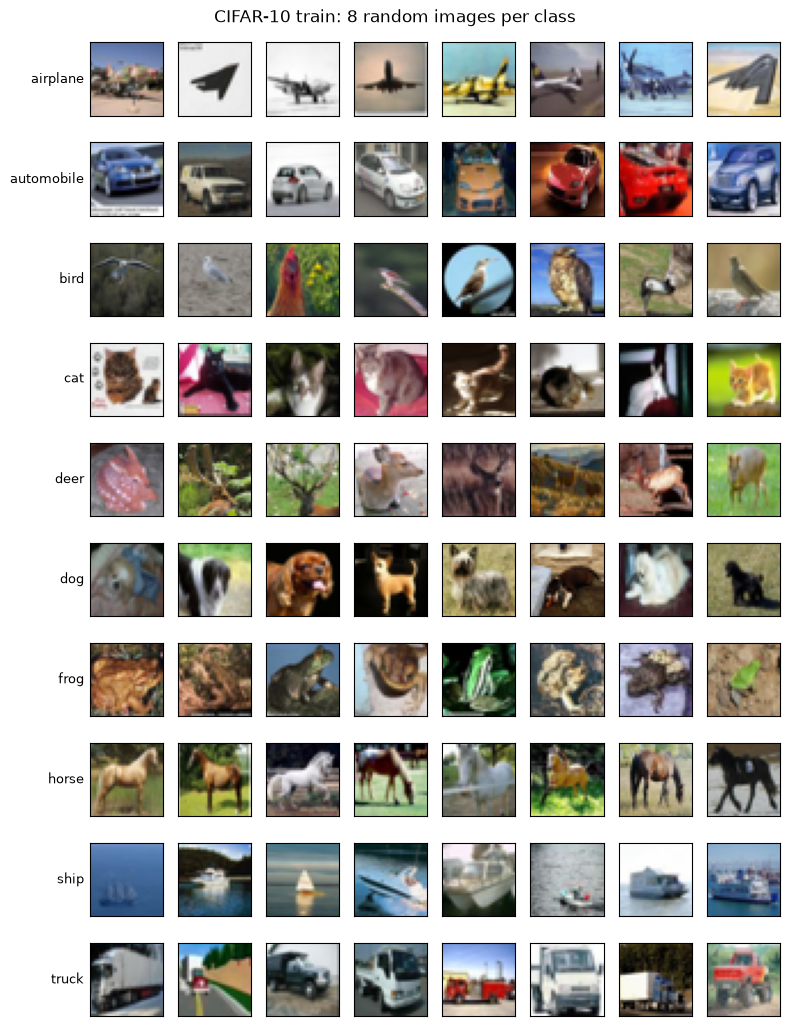

In [7]:
show_grid(c10.data, labels_c10, c10.classes, range(10),                   # all 10 CIFAR-10 classes
          title="CIFAR-10 train: 8 random images per class")              # data is already H × W × 3

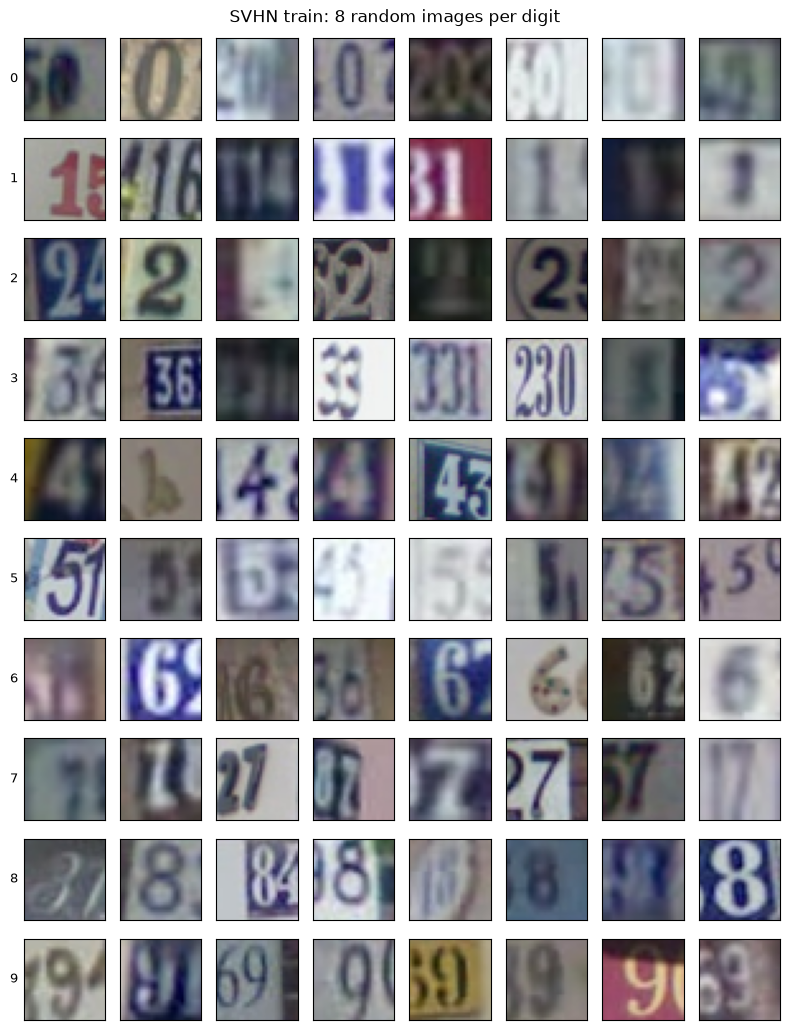

In [8]:
svhn_hwc = svhn.data.transpose(0, 2, 3, 1)                                # (N, 3, 32, 32) → (N, 32, 32, 3) for imshow; a view, no copy
show_grid(svhn_hwc, labels_svhn, svhn.classes, range(10),                 # all 10 digits
          title="SVHN train: 8 random images per digit")                  # label = the digit in the center

CIFAR-100 and CIFAR-10 were built with **no shared classes**. The grid below shows the CIFAR-100 classes that look most like a CIFAR-10 class, then 10 random others for contrast.

| CIFAR-10 class | Closest CIFAR-100 classes |
|---|---|
| airplane | rocket (no aircraft class) |
| automobile | pickup_truck, streetcar |
| bird | none (CIFAR-100 has no birds) |
| cat | leopard, tiger, lion |
| deer | cattle, camel, kangaroo |
| dog | wolf, fox |
| frog | lizard, turtle |
| horse | camel, cattle |
| ship | none (CIFAR-100 has no boats) |
| truck | bus, tractor, pickup_truck |

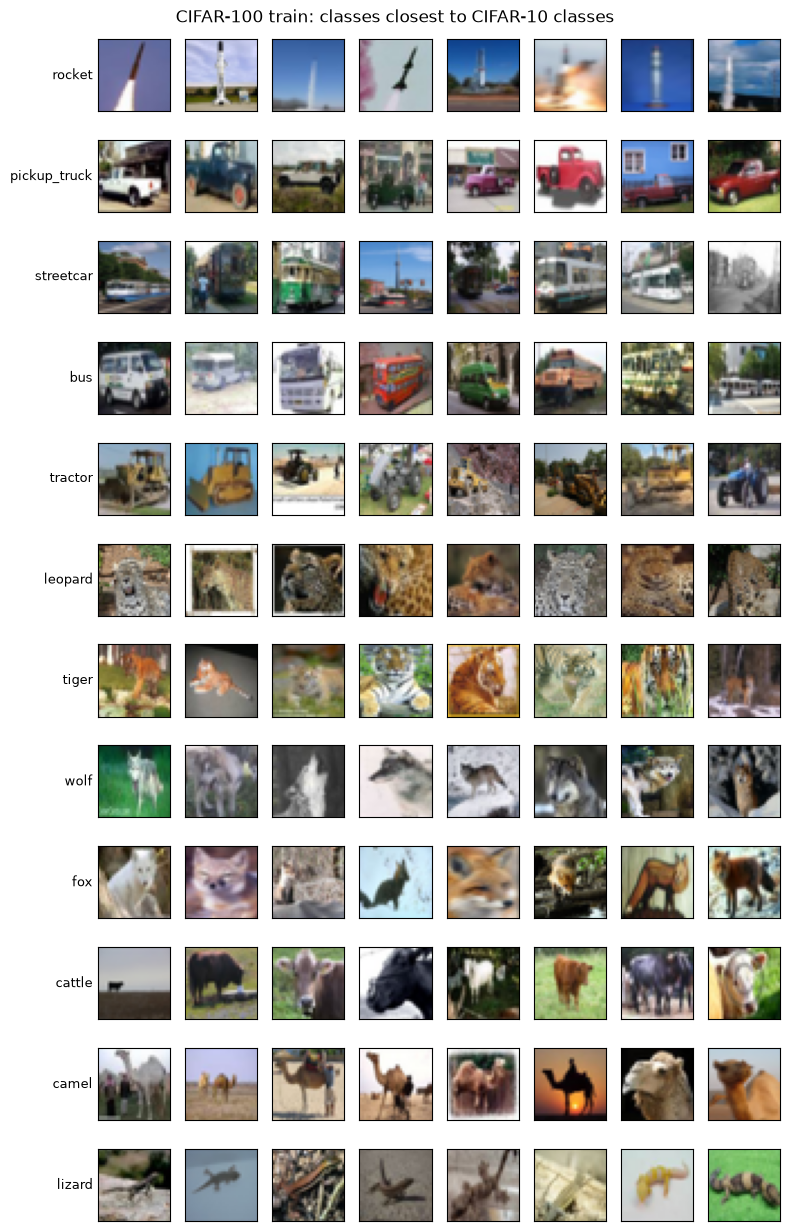

In [9]:
c100_close = ["rocket", "pickup_truck", "streetcar", "bus", "tractor",    # vehicles closest to CIFAR-10's vehicles
              "leopard", "tiger", "wolf", "fox", "cattle", "camel", "lizard"]  # animals closest to CIFAR-10's animals
close_ids = [c100.classes.index(name) for name in c100_close]              # class names → label numbers
show_grid(c100.data, labels_c100, c100.classes, close_ids,                # one row per chosen class
          title="CIFAR-100 train: classes closest to CIFAR-10 classes")

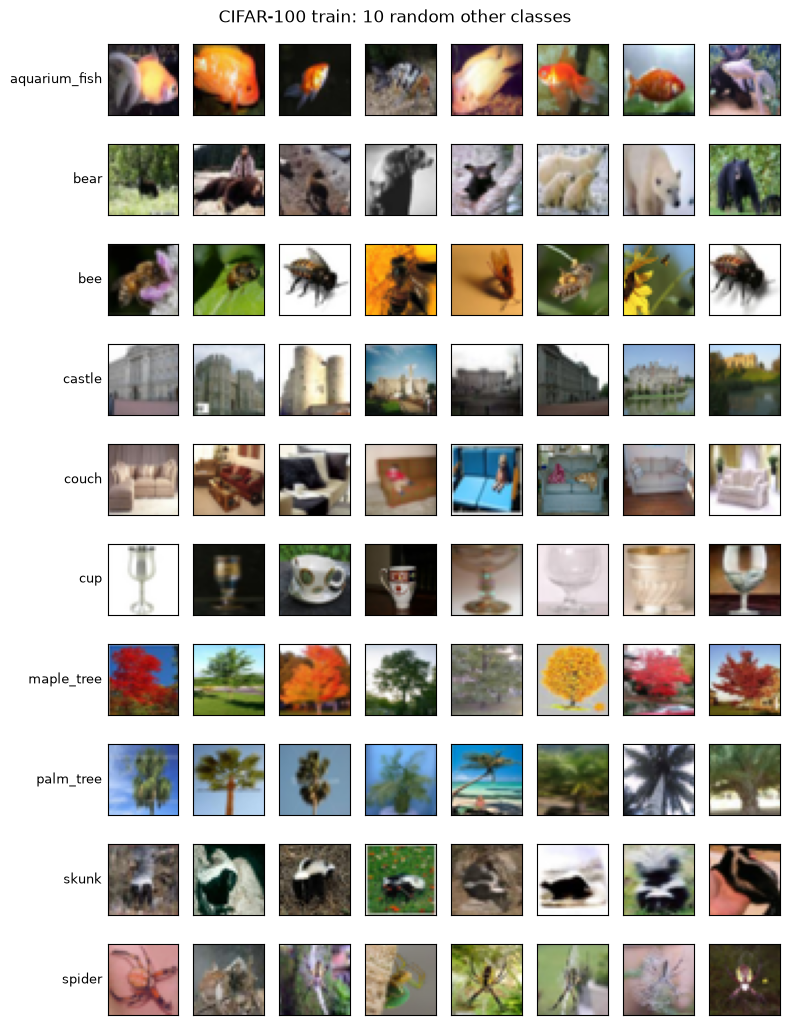

In [10]:
rng = np.random.default_rng(SEED)                                          # fixed seed: the same classes every run
other_ids = sorted(rng.choice([k for k in range(100) if k not in close_ids],  # all classes not shown above
                              10, replace=False))                          # pick 10 of them
show_grid(c100.data, labels_c100, c100.classes, other_ids,                # one row per random class
          title="CIFAR-100 train: 10 random other classes")

**Observed (grids)**
- CIFAR-10 and CIFAR-100 images look correct: one centered object per image, labels match the pictures, varied backgrounds and viewpoints.
- SVHN: the labeled digit is in the center, but **neighboring digits are often partly visible at the edges** (e.g. "15" in the row for 1, "24" in the row for 2). Many crops are blurry, dark or low-contrast.
- CIFAR-100 has no class that matches a CIFAR-10 class exactly, but several are close: pickup_truck/bus/tractor ↔ automobile/truck; leopard/tiger ↔ cat; wolf/fox ↔ dog; cattle/camel ↔ deer/horse; lizard ↔ frog. **Bird and ship have no CIFAR-100 counterpart at all.** So C learns related, not identical, visual concepts: a fair "pretrained but not on CIFAR-10" control.

## 3. Class counts

**Looking for:** CIFAR-10 and CIFAR-100 exactly balanced; how unbalanced SVHN is.

**Feeds:** whether SVHN imbalance needs to be mentioned when reading stage-2 SVHN accuracy.

In [11]:
def count_summary(name, labels, n_classes):
    """Print how balanced the classes are; return images per class."""
    c = np.bincount(labels, minlength=n_classes)                           # c[k] = number of images with label k
    print(f"{name:<10} min={c.min():>6}  max={c.max():>6}  max/min={c.max() / c.min():.2f}")  # balance in one line
    return c                                                               # keep the counts for the plot below

print("=== Images per class: train ===")                                  # title for this check
cnt_c10 = count_summary("CIFAR-10", labels_c10, 10)                       # expected exactly 5000 each
cnt_c100 = count_summary("CIFAR-100", labels_c100, 100)                   # expected exactly 500 each
cnt_svhn = count_summary("SVHN", labels_svhn, 10)                         # expected unbalanced
print()                                                                   # blank line between checks

print("=== Images per class: test ===")                                   # title for this check
count_summary("CIFAR-10", labels_c10_test, 10)                            # expected exactly 1000 each
count_summary("CIFAR-100", labels_c100_test, 100)                         # expected exactly 100 each
cnt_svhn_test = count_summary("SVHN", labels_svhn_test, 10)               # expected unbalanced
print()                                                                   # blank line between checks

share_train = cnt_svhn / cnt_svhn.sum()                                   # fraction of SVHN train images per digit
share_test = cnt_svhn_test / cnt_svhn_test.sum()                          # fraction of SVHN test images per digit
majority = share_train.argmax()                                           # the most common digit in train
print("=== SVHN: what 'chance' really is ===")                            # title for this check
print(f"Most common train digit: {majority} ({share_train[majority]:.1%} of train)")  # the digit a lazy model would always guess
print(f"Always guessing it scores {share_test[majority]:.1%} on SVHN test (uniform chance would be 10%)")  # real floor for stage-2 accuracy

=== Images per class: train ===
CIFAR-10   min=  5000  max=  5000  max/min=1.00
CIFAR-100  min=   500  max=   500  max/min=1.00
SVHN       min=  4659  max= 13861  max/min=2.98

=== Images per class: test ===
CIFAR-10   min=  1000  max=  1000  max/min=1.00
CIFAR-100  min=   100  max=   100  max/min=1.00
SVHN       min=  1595  max=  5099  max/min=3.20

=== SVHN: what 'chance' really is ===
Most common train digit: 1 (18.9% of train)
Always guessing it scores 19.6% on SVHN test (uniform chance would be 10%)


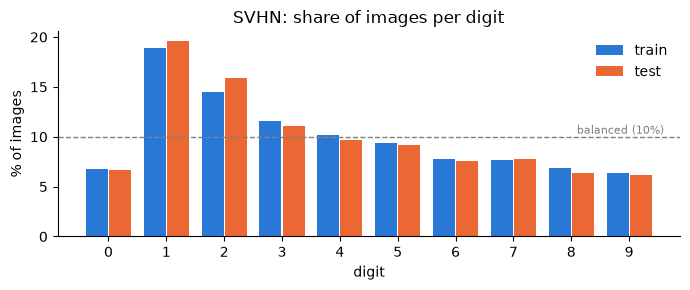

In [12]:
x = np.arange(10)                                                         # one position per digit
fig, ax = plt.subplots(figsize=(7, 3))                                    # one wide, short plot
ax.bar(x - 0.2, share_train * 100, width=0.38, label="train", color="#2a78d6")  # train share per digit (left bar)
ax.bar(x + 0.2, share_test * 100, width=0.38, label="test", color="#eb6834")    # test share per digit (right bar)
ax.axhline(10, color="gray", linewidth=1, linestyle="--")                 # 10% = what a balanced dataset would have
ax.text(9.6, 10.3, "balanced (10%)", ha="right", fontsize=8, color="gray")  # label the reference line
ax.set_xticks(x)                                                          # one tick per digit
ax.set_xlabel("digit")                                                    # x-axis name
ax.set_ylabel("% of images")                                              # y-axis name
ax.set_title("SVHN: share of images per digit")                           # plot title
ax.legend(frameon=False)                                                  # which bar is train and which is test
ax.spines[["top", "right"]].set_visible(False)                            # remove the box around the plot
plt.tight_layout()                                                        # fit labels inside the figure
plt.show()                                                                # display the figure

**Observed (class counts)**
- CIFAR-10 and CIFAR-100 are perfectly balanced in train and test.
- SVHN is unbalanced (max/min ≈ 3): digit 1 is ~19% of the data, digit 2 ~15%, digits 0 and 6–9 only ~6–8% each. Train and test have nearly the same distribution.
- Always guessing "1" scores **19.6%** on SVHN test. That, not 10%, is the floor for reading stage-2 SVHN accuracy.

## 4. Per-channel mean and std

**Looking for:** the RGB mean and std of each dataset's training set, and how far SVHN's are from CIFAR-10's.

**Feeds:** one normalization (CIFAR-10's values) for all stages.

In [13]:
def channel_stats(data, channel_axis):
    """Per-channel mean and std over every pixel of every image, on the 0–1 scale."""
    mean, std = [], []                                                    # one value per channel (R, G, B)
    for c in range(3):                                                    # go through R, G, B
        x = np.take(data, c, axis=channel_axis).astype(np.float32) / 255  # all values of channel c, scaled to 0–1
        mean.append(float(x.mean()))                                      # average brightness of this channel
        std.append(float(x.std()))                                        # spread of this channel
    return np.array(mean), np.array(std)                                  # as arrays so we can do math on them

stats = {                                                                 # dataset name → (mean, std), train sets only
    "CIFAR-10": channel_stats(c10.data, channel_axis=3),                  # CIFAR: channels are the last axis
    "CIFAR-100": channel_stats(c100.data, channel_axis=3),                # same layout as CIFAR-10
    "SVHN": channel_stats(svhn.data, channel_axis=1),                     # SVHN: channels are axis 1
}

print("=== Per-channel mean and std (train, 0–1 scale) ===")             # title for this check
print(f"{'':<10} {'mean (R, G, B)':<26} std (R, G, B)")                   # column headers
for name, (m, s) in stats.items():                                        # one row per dataset
    print(f"{name:<10} {np.round(m, 4)!s:<26} {np.round(s, 4)}")          # rounded to 4 decimals
print()                                                                   # blank line between checks
print("Commonly published CIFAR-10 values: mean (0.4914, 0.4822, 0.4465), std (0.2470, 0.2435, 0.2616)")  # cross-check
print("(Another often-copied std, (0.2023, 0.1994, 0.2010), is not the dataset-wide std; we use our own values.)")  # known pitfall

=== Per-channel mean and std (train, 0–1 scale) ===
           mean (R, G, B)             std (R, G, B)
CIFAR-10   [0.4914 0.4822 0.4465]     [0.247  0.2435 0.2616]
CIFAR-100  [0.5071 0.4865 0.4409]     [0.2673 0.2564 0.2762]
SVHN       [0.4377 0.4438 0.4728]     [0.198 0.201 0.197]

Commonly published CIFAR-10 values: mean (0.4914, 0.4822, 0.4465), std (0.2470, 0.2435, 0.2616)
(Another often-copied std, (0.2023, 0.1994, 0.2010), is not the dataset-wide std; we use our own values.)


In [14]:
c10_mean, c10_std = stats["CIFAR-10"]                                     # the one normalization used in every stage

print("=== What each dataset looks like after CIFAR-10 normalization ===")  # title for this check
print("(perfectly matched data would be mean 0, std 1 in every channel)")    # what to compare against
for name, (m, s) in stats.items():                                        # one row per dataset
    new_mean = (m - c10_mean) / c10_std                                   # where this dataset's average lands after normalizing
    new_std = s / c10_std                                                 # how spread out it is after normalizing
    print(f"{name:<10} mean {np.round(new_mean, 2)!s:<22} std {np.round(new_std, 2)}")  # one line per dataset

=== What each dataset looks like after CIFAR-10 normalization ===
(perfectly matched data would be mean 0, std 1 in every channel)
CIFAR-10   mean [0. 0. 0.]             std [1. 1. 1.]
CIFAR-100  mean [ 0.06  0.02 -0.02]    std [1.08 1.05 1.06]
SVHN       mean [-0.22 -0.16  0.1 ]    std [0.8  0.83 0.75]


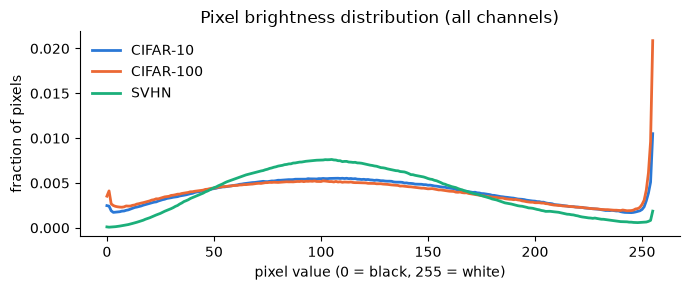

In [15]:
fig, ax = plt.subplots(figsize=(7, 3))                                    # one wide, short plot
bins = np.arange(257)                                                     # one bin per pixel value 0–255
for name, data in [("CIFAR-10", c10.data), ("CIFAR-100", c100.data), ("SVHN", svhn.data)]:  # same order as the colors
    sample = data[:10000].ravel()                                         # all pixel values of the first 10k images, every channel
    hist, _ = np.histogram(sample, bins=bins, density=True)               # fraction of values at each brightness
    ax.plot(bins[:-1], hist, label=name, color=COLORS[name], linewidth=2) # one line per dataset
ax.set_xlabel("pixel value (0 = black, 255 = white)")                     # x-axis name
ax.set_ylabel("fraction of pixels")                                       # y-axis name
ax.set_title("Pixel brightness distribution (all channels)")              # plot title
ax.legend(frameon=False)                                                  # which line is which dataset
ax.spines[["top", "right"]].set_visible(False)                            # remove the box around the plot
plt.tight_layout()                                                        # fit labels inside the figure
plt.show()                                                                # display the figure

**Observed (mean / std)**
- Our CIFAR-10 values match the published ones to 4 decimals: mean (0.4914, 0.4822, 0.4465), std (0.2470, 0.2435, 0.2616).
- CIFAR-100 is almost the same as CIFAR-10 after normalization (mean within ±0.06, std ~1.06). Arm C's stage 1 sees essentially the same input statistics as arm A's.
- SVHN is off-center and narrower: mean (−0.22, −0.16, +0.10), std ~0.8. The histogram shows why: SVHN is mostly mid-tones with few pure blacks or whites, while CIFAR has a spike of saturated white pixels.
- The shift is small (well under one std), so one shared normalization is fine. Note for later: BatchNorm's running statistics will shift toward SVHN in stage 2, so the probe must use the backbone as it is at that checkpoint (eval mode).

## 5. Augmentation preview

**Looking for:** random crop 32 (padding 4) + horizontal flip on CIFAR, crop only on SVHN. Augmented images still look sensible; no flipped digits.

**Feeds:** checks the transforms before the baseline uses them.

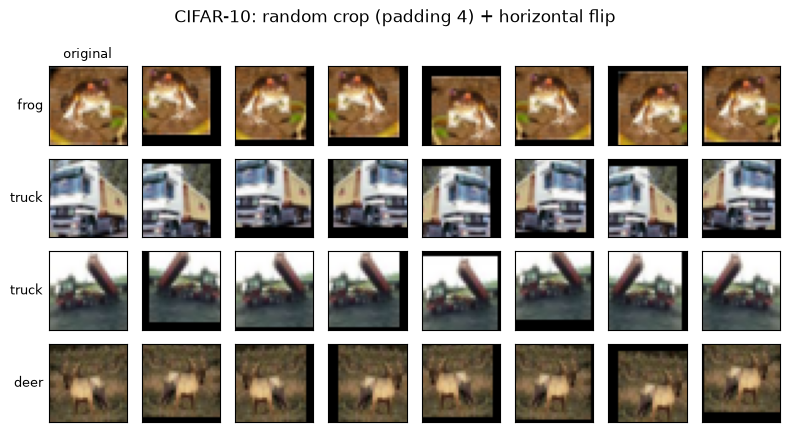

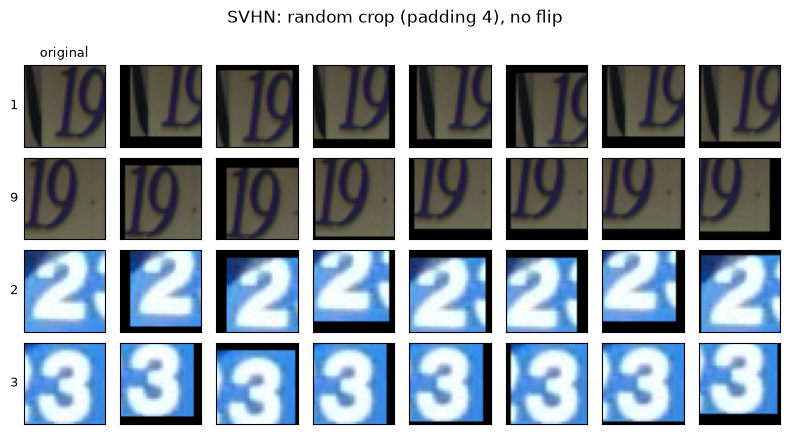

In [16]:
aug_cifar = T.Compose([T.RandomCrop(32, padding=4),                       # pad 4 black pixels on each side, cut a random 32×32 window
                       T.RandomHorizontalFlip()])                         # mirror left-right with probability 0.5
aug_svhn = T.RandomCrop(32, padding=4)                                    # SVHN: same crop, no flip

def show_augmented(dataset, indices, aug, n=7, title=""):
    """Each row: the original image, then n random augmented versions of it."""
    torch.manual_seed(SEED)                                               # torchvision transforms draw from torch's random generator
    fig, axes = plt.subplots(len(indices), n + 1,                         # one row per image, original + n versions
                             figsize=((n + 1) * 1.0, len(indices) * 1.1))  # about 1 inch per image
    for row, i in enumerate(indices):                                     # go through the chosen images
        img, label = dataset[i]                                           # PIL image and its label (no transform on the dataset)
        axes[row, 0].imshow(img)                                          # first column: the original
        axes[row, 0].set_ylabel(dataset.classes[label], rotation=0,       # class name to the left of the row
                                ha="right", va="center", fontsize=9)      # right-aligned, vertically centered
        for col in range(1, n + 1):                                       # the remaining columns
            axes[row, col].imshow(aug(img))                               # a new random crop (and flip) each call
        for ax in axes[row]:                                              # every image in this row
            ax.set_xticks([])                                             # hide x-axis ticks
            ax.set_yticks([])                                             # hide y-axis ticks
    axes[0, 0].set_title("original", fontsize=9)                          # mark the first column once
    fig.suptitle(title)                                                   # title above the grid
    plt.tight_layout()                                                    # remove extra space
    plt.show()                                                            # display the figure

show_augmented(c10, [0, 1, 2, 3], aug_cifar,                              # first 4 CIFAR-10 train images
               title="CIFAR-10: random crop (padding 4) + horizontal flip")
show_augmented(svhn, [0, 1, 2, 3], aug_svhn,                              # first 4 SVHN train images
               title="SVHN: random crop (padding 4), no flip")

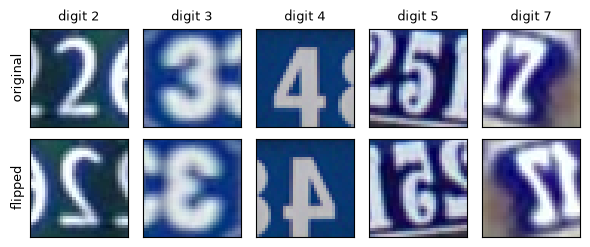

In [17]:
# Why SVHN gets no flip: mirrored digits are not valid digits (and some look like other digits)
digits = [2, 3, 4, 5, 7]                                                  # digits that change clearly when mirrored
first = [np.flatnonzero(labels_svhn == d)[:500] for d in digits]          # the first 500 train images of each digit
idx = [ids[svhn.data[ids].std(axis=(1, 2, 3)).argmax()] for ids in first]  # per digit, the highest-contrast (clearest) one
fig, axes = plt.subplots(2, len(digits), figsize=(len(digits) * 1.2, 2.6))  # top row original, bottom row flipped
for col, i in enumerate(idx):                                             # go through the chosen images
    img, label = svhn[i]                                                  # PIL image and its label
    axes[0, col].imshow(img)                                              # original digit
    axes[1, col].imshow(T.functional.hflip(img))                          # the same image mirrored left-right
    axes[0, col].set_title(f"digit {label}", fontsize=9)                  # label above each column
for ax in axes.ravel():                                                   # every subplot
    ax.set_xticks([])                                                     # hide x-axis ticks
    ax.set_yticks([])                                                     # hide y-axis ticks
axes[0, 0].set_ylabel("original", fontsize=9)                             # name the top row
axes[1, 0].set_ylabel("flipped", fontsize=9)                              # name the bottom row
plt.tight_layout()                                                        # remove extra space
plt.show()                                                                # display the figure

**Observed (augmentation)**
- Crops with padding 4 add black borders of up to 4 pixels; the object always stays recognizable. CIFAR flips look natural.
- SVHN crops sometimes push a neighboring digit further into view, but the center digit stays dominant.
- Flipped digits are not valid digits (a mirrored 2 or 3 is a different shape), confirming no flip for SVHN.

## 6. Data-loading speed

**Looking for:** seconds for one full pass over CIFAR-10 with a DataLoader (with augmentation, batch size 128), for a few `num_workers` values.

**Feeds:** whether data loading limits training speed; input to the cost estimate.

In [18]:
train_tf = T.Compose([                                                    # the full CIFAR training pipeline, as the baseline will use it
    T.RandomCrop(32, padding=4),                                          # random crop
    T.RandomHorizontalFlip(),                                             # random flip
    T.ToTensor(),                                                         # PIL image (0–255) → float tensor (0–1), shape 3 × 32 × 32
    T.Normalize(c10_mean.tolist(), c10_std.tolist()),                     # CIFAR-10 normalization from section 4
])
c10_aug = datasets.CIFAR10(DATA, train=True, download=False, transform=train_tf)  # CIFAR-10 train with the pipeline attached

speed = {}                                                                # num_workers → (epoch 1 seconds, epoch 2 seconds)
for workers in [0, 2, 4, 8]:                                              # number of background processes preparing batches
    loader = DataLoader(c10_aug, batch_size=128, shuffle=True,            # same batch size as training
                        num_workers=workers,                              # 0 = everything in this process
                        persistent_workers=workers > 0)                   # keep workers alive between epochs, as in training
    times = []                                                            # seconds per epoch
    for epoch in range(2):                                                # epoch 1 includes starting the workers; epoch 2 does not
        t0 = time.perf_counter()                                          # start the clock
        for x, y in loader:                                               # pull every batch (no model, only loading)
            pass                                                          # do nothing with it
        times.append(time.perf_counter() - t0)                            # stop the clock
    speed[workers] = times                                                # store both epochs
    print(f"num_workers={workers}: epoch 1 {times[0]:5.1f} s, epoch 2 {times[1]:5.1f} s "  # time per epoch
          f"({times[1] / len(loader) * 1000:4.1f} ms per batch)")         # per batch, to compare with the training step later
    del loader                                                            # shut the workers down before the next setting

num_workers=0: epoch 1   2.2 s, epoch 2   2.2 s ( 5.7 ms per batch)


num_workers=2: epoch 1   3.6 s, epoch 2   1.1 s ( 2.9 ms per batch)


num_workers=4: epoch 1   4.8 s, epoch 2   0.6 s ( 1.5 ms per batch)


num_workers=8: epoch 1   9.1 s, epoch 2   0.3 s ( 0.8 ms per batch)


**Observed (loading speed)**
- One full CIFAR-10 epoch (50k images, crop + flip + normalize, batch 128) takes 2.2 s with no workers, and 0.3–1.1 s with 2–8 workers after they have started.
- Starting workers costs time (epoch 1 is slower with more workers); `persistent_workers=True` pays this once per run, not every epoch.
- Even with 0 workers, loading takes ~6 ms per batch. Compare this with the ResNet-18 training step on MPS once the baseline runs: if the step is much slower than this, data loading is not the bottleneck.

## Findings

- **1. Verify:** all counts, shapes and label ranges as expected (CIFAR-10 and CIFAR-100 50k/10k, SVHN 73,257/26,032; labels 0–9 / 0–99 / 0–9). CIFAR arrays are H×W×C, SVHN is C×H×W (transpose before plotting).
- **2. Grids:** images and labels look right. SVHN shows neighboring digits at the edges and many blurry crops. CIFAR-100 has no exact CIFAR-10 class; the closest are vehicles (pickup_truck, bus, tractor) and animals (leopard, tiger, wolf, fox, cattle, camel, lizard); nothing for bird or ship.
- **3. Class counts:** CIFAR-10/100 perfectly balanced. SVHN unbalanced (max/min ≈ 3, digit 1 ≈ 19%); majority-class accuracy on SVHN test = 19.6%.
- **4. Mean / std:** CIFAR-10 mean (0.4914, 0.4822, 0.4465), std (0.2470, 0.2435, 0.2616), matching published values. CIFAR-100 nearly identical; SVHN after CIFAR-10 normalization has mean ≈ (−0.22, −0.16, 0.10), std ≈ 0.8.
- **5. Augmentation:** crop (padding 4) + flip works as intended on CIFAR; crop only on SVHN; flipped digits confirmed invalid.
- **6. Loading speed:** 2.2 s per CIFAR-10 epoch with 0 workers; 0.3 s with 8 persistent workers (about 9 s one-time startup; timings vary a little between runs).

**Decisions:**
- Use the computed CIFAR-10 normalization above for every stage and arm.
- When reporting stage-2 SVHN accuracy, state the 19.6% majority-class floor next to it.
- Keep SVHN without flip; keep the CIFAR-style crop + flip for CIFAR-10 and CIFAR-100.
- Start with `num_workers=4`, `persistent_workers=True`; revisit only if the training step turns out to be faster than loading.
- Open, not decided here: whether the 40k pretrain pool and the never-seen 5k should be split per class (stratified). The data is balanced, so a stratified split is easy; decide in the split script.